# Parcial práctico 1 — Machine Learning: entrenamiento e inferencia mediante Streamlit

## Predicción del nivel de ingreso anual (> 50K USD) — Dataset *Adult / Census Income* (UCI)

**Maestría en Inteligencia Artificial y Ciencia de Datos — Aprendizaje Automático**

**Integrantes:**
- Angie Tatiana Rodríguez Duque
- Kevin Fernando Rodríguez Duque

**Dataset (catálogo del parcial, opción 7 — Clasificación):** Adult / Census Income — UCI Machine Learning Repository
- Ficha oficial: https://archive.ics.uci.edu/dataset/2/adult
- Descarga directa (ZIP oficial): https://archive.ics.uci.edu/static/public/2/adult.zip
- Licencia: CC BY 4.0. Cita: Becker, B. & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20

### Descripción del problema
El dataset contiene 48 842 registros del censo de EE. UU. de 1994 con características demográficas y laborales de cada persona (edad, educación, ocupación, estado civil, horas trabajadas, ganancias de capital, etc.). El objetivo es **predecir si una persona gana más de 50 000 USD al año** a partir de esas características.

| Elemento | Definición |
|---|---|
| Tipo de aprendizaje | Supervisado |
| Tipo de problema | **Clasificación binaria** |
| Variable objetivo (y) | `income` → 1 si `>50K`, 0 si `<=50K` |
| Variables predictoras (X) | 12: `age`, `workclass`, `education`, `marital_status`, `occupation`, `relationship`, `race`, `sex`, `capital_gain`, `capital_loss`, `hours_per_week`, `native_country` |
| Variables excluidas | `fnlwgt` (peso muestral del censo, no es un atributo de la persona) y `education_num` (codificación numérica 1 a 1 de `education`, redundante) |

### Objetivo general
Entrenar, evaluar y comparar dos algoritmos de clasificación —**Random Forest** y **Perceptrón multicapa (MLP)**—, cada uno con **dos variaciones de hiperparámetros** elegidas mediante validación cruzada, para predecir el nivel de ingreso, guardar los modelos con su preprocesamiento (Pipelines de scikit-learn) y usarlos para inferencia en una aplicación Streamlit sin volver a entrenarlos.

### Utilidad práctica
Estimar el nivel de ingreso a partir de información demográfica sirve, por ejemplo, para segmentar clientes en banca y seguros, focalizar programas sociales o estimar capacidad de pago cuando no se dispone del ingreso declarado. *(Nota ética: el modelo aprende patrones de 1994, incluidas desigualdades por sexo y raza; no debe usarse para decisiones individuales sin auditoría de sesgos.)*

## Celda 2. Importación de bibliotecas
Solo se usan bibliotecas estándar de ciencia de datos disponibles en Google Colab: `pandas`/`numpy` (datos), `matplotlib`/`seaborn` (gráficas), `scikit-learn` (preprocesamiento, modelos y métricas) y `joblib` (guardado de modelos). No se usa XGBoost ni TensorFlow para mantener el proyecto liviano: el MLP se implementa con `sklearn.neural_network.MLPClassifier`, lo que permite guardarlo dentro de un Pipeline con `joblib`.

In [1]:
# Celda 2 — Bibliotecas
import json
import time
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| joblib", joblib.__version__)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | joblib 1.6.0


## Celda 3. Descarga y carga de los datos
La celda descarga el ZIP **oficial** de UCI y lo descomprime en la carpeta `datos/`. El ZIP contiene:
- `adult.data` (32 561 registros, partición original de entrenamiento),
- `adult.test` (16 281 registros, partición original de prueba; su primera línea es un comentario y las etiquetas terminan en punto, p. ej. `>50K.`),
- `adult.names` (descripción de las variables).

Los archivos no tienen encabezado, por eso se asignan los nombres de columna según `adult.names`. Los valores faltantes vienen codificados como `?` y se leen directamente como `NaN` (`na_values="?"`).

**Si la descarga automática falla** (sin internet o UCI caído): descargue manualmente el ZIP desde https://archive.ics.uci.edu/dataset/2/adult (botón *DOWNLOAD*), y en Colab súbalo con el ícono de carpeta (panel izquierdo) → *Subir* a la carpeta `datos/`, o ejecute la celda de nuevo: si encuentra `datos/adult.zip` lo descomprime sin descargar.

Las particiones originales `adult.data` y `adult.test` se **unen** en un solo DataFrame para luego hacer nuestra propia división 80/20 estratificada (Celda 7), tal como pide el taller.

In [2]:
# Celda 3 — Descarga y carga de los datos
URL_FICHA = "https://archive.ics.uci.edu/dataset/2/adult"
URL_ZIP = "https://archive.ics.uci.edu/static/public/2/adult.zip"

DIR_DATOS = Path("datos")
DIR_MODELOS = Path("modelos")
DIR_DATOS.mkdir(exist_ok=True)
DIR_MODELOS.mkdir(exist_ok=True)

ruta_zip = DIR_DATOS / "adult.zip"
if not (DIR_DATOS / "adult.data").exists():
    try:
        if not ruta_zip.exists():
            print("Descargando", URL_ZIP, "...")
            urllib.request.urlretrieve(URL_ZIP, ruta_zip)
        with zipfile.ZipFile(ruta_zip) as z:
            z.extractall(DIR_DATOS)
        print("Descarga y extracción correctas.")
    except Exception as e:
        print("No fue posible descargar automáticamente:", e)
        print("Descargue el ZIP desde", URL_FICHA, "y súbalo a la carpeta 'datos/'.")
else:
    print("Los archivos ya existen en 'datos/'; no se descargan de nuevo.")

COLUMNAS = ["age", "workclass", "fnlwgt", "education", "education_num",
            "marital_status", "occupation", "relationship", "race", "sex",
            "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]

lectura = dict(header=None, names=COLUMNAS, skipinitialspace=True, na_values="?")
df_train_orig = pd.read_csv(DIR_DATOS / "adult.data", **lectura)
df_test_orig = pd.read_csv(DIR_DATOS / "adult.test", skiprows=1, **lectura)  # 1.ª línea = comentario

df = pd.concat([df_train_orig, df_test_orig], ignore_index=True)

# Verificación de la lectura
print("adult.data:", df_train_orig.shape, "| adult.test:", df_test_orig.shape, "| unido:", df.shape)
assert df.shape == (48842, 15), "El número de filas/columnas no coincide con la ficha de UCI (48 842 x 15)"
print("Lectura verificada: 48 842 registros y 15 columnas, como indica la ficha oficial.")

Los archivos ya existen en 'datos/'; no se descargan de nuevo.
adult.data: (32561, 15) | adult.test: (16281, 15) | unido: (48842, 15)
Lectura verificada: 48 842 registros y 15 columnas, como indica la ficha oficial.


## Celda 4. Exploración inicial
Se revisan primeras filas, dimensiones, nombres y tipos de variables, estadísticas descriptivas, duplicados y faltantes. Al revisar la variable objetivo aparece una **inconsistencia de formato**: en `adult.test` las etiquetas terminan en punto (`<=50K.` / `>50K.`). Se corrige quitando el punto; esto no es fuga de información, solo unifica la escritura de las dos etiquetas.

In [3]:
# Celda 4 — Exploración inicial
print("Primeras filas:")
display(df.head())

print("\nFilas y columnas:", df.shape)
print("\nNombres de las variables:", list(df.columns))

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nEstadísticas descriptivas (numéricas):")
display(df.describe().T.round(2))

print("\nEstadísticas descriptivas (categóricas):")
display(df.select_dtypes(exclude="number").describe().T)


faltantes = df.isna().sum()
faltantes = pd.DataFrame({"faltantes": faltantes, "porcentaje_%": (faltantes / len(df) * 100).round(2)})
print("\nValores faltantes por variable:")
display(faltantes[faltantes["faltantes"] > 0])

print("\nEtiquetas originales de la variable objetivo:")
print(df["income"].value_counts())

# Corrección de formato de la etiqueta (">50K." -> ">50K")
df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
print("\nEtiquetas después de unificar el formato:")
print(df["income"].value_counts())

# Los duplicados se cuentan DESPUÉS de unificar la etiqueta (antes, ">50K" y ">50K." parecían distintos)
print("\nRegistros duplicados (filas completamente iguales):", df.duplicated().sum())

Primeras filas:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Filas y columnas: (48842, 15)

Nombres de las variables: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

Tipos de datos:


,tipo
age,int64
workclass,str
fnlwgt,int64
education,str
education_num,int64
marital_status,str
occupation,str
relationship,str
race,str
sex,str



Estadísticas descriptivas (numéricas):


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0



Estadísticas descriptivas (categóricas):


,count,unique,top,freq
workclass,46043,8,Private,33906
education,48842,16,HS-grad,15784
marital_status,48842,7,Married-civ-spouse,22379
occupation,46033,14,Prof-specialty,6172
relationship,48842,6,Husband,19716
race,48842,5,White,41762
sex,48842,2,Male,32650
native_country,47985,41,United-States,43832
income,48842,4,<=50K,24720



Valores faltantes por variable:


,faltantes,porcentaje_%
workclass,2799,5.73
occupation,2809,5.75
native_country,857,1.75



Etiquetas originales de la variable objetivo:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

Etiquetas después de unificar el formato:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Registros duplicados (filas completamente iguales): 52


## Celda 5. Análisis exploratorio de datos (EDA)
Gráficas: (1) distribución de la variable objetivo, (2) distribución de variables numéricas por clase, (3) tasa de ingreso alto según las variables categóricas principales y (4) correlaciones entre variables numéricas. Debajo de cada bloque se imprime una lectura breve calculada con los datos.

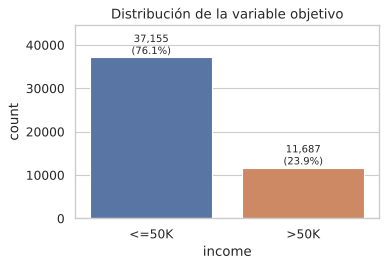

Clases desbalanceadas: 23.9% de las personas gana >50K. Por eso se estratifica la división y se priorizan precision/recall sobre la exactitud.


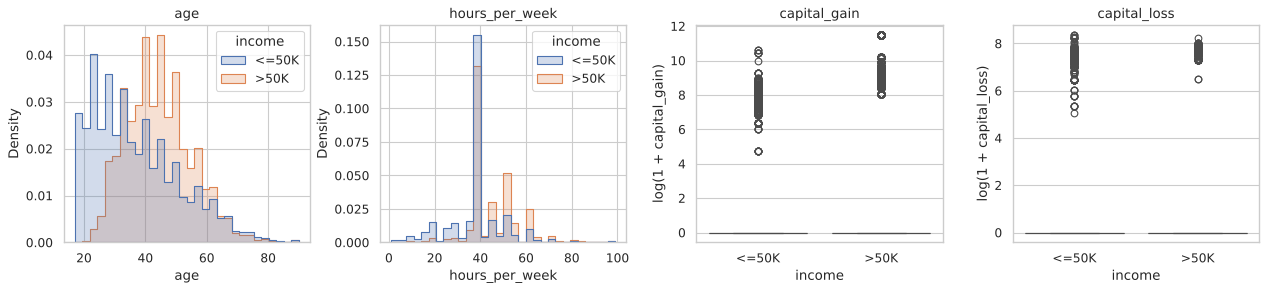

         age  hours_per_week  capital_gain  capital_loss
income                                                  
<=50K   34.0            40.0           0.0           0.0
>50K    43.0            40.0           0.0           0.0
% con capital_gain = 0: 91.7% | % con capital_loss = 0: 95.3% → variables muy sesgadas (se aplica log1p).


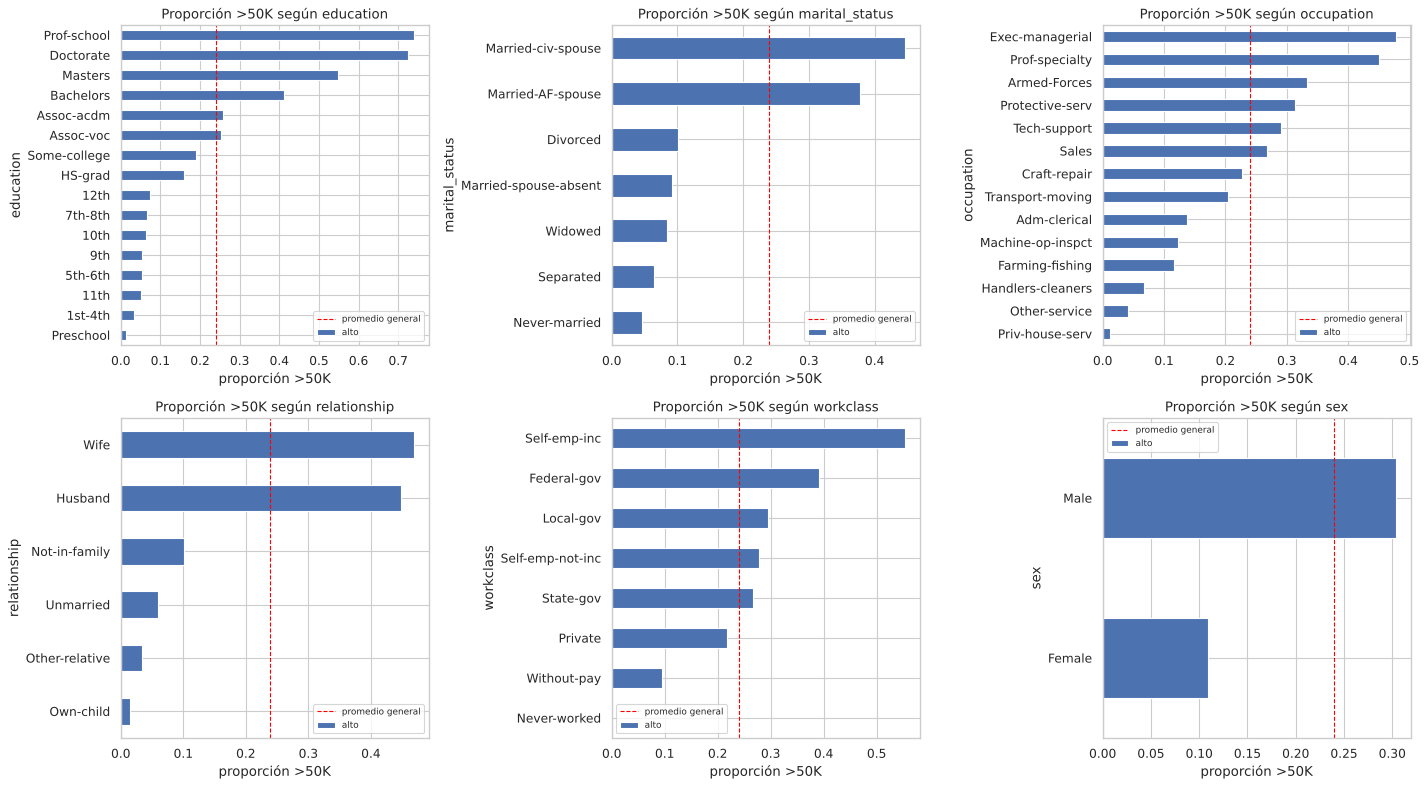

marital_status: mayor tasa → Married-civ-spouse (44.6%); menor tasa → Never-married (4.5%)
education: mayor tasa → Prof-school (74.0%); menor tasa → Preschool (1.2%)
sex: mayor tasa → Male (30.4%); menor tasa → Female (10.9%)


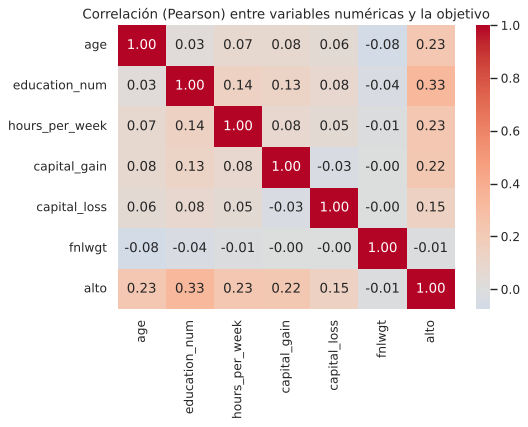

Correlación con la objetivo: {'age': 0.23, 'education_num': 0.333, 'hours_per_week': 0.228, 'capital_gain': 0.223, 'capital_loss': 0.148, 'fnlwgt': -0.006}
fnlwgt prácticamente no se relaciona con el ingreso (es un peso muestral del censo) → se excluye.


In [4]:
# Celda 5 — EDA
# 1) Distribución de la variable objetivo
conteo = df["income"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="income", hue="income", order=["<=50K", ">50K"], ax=ax, legend=False,
              palette={"<=50K": "#4C72B0", ">50K": "#DD8452"})
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}\n({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la variable objetivo")
ax.set_ylim(0, conteo.max() * 1.2)
plt.tight_layout(); plt.show()
print(f"Clases desbalanceadas: {conteo['>50K']/len(df):.1%} de las personas gana >50K. "
      "Por eso se estratifica la división y se priorizan precision/recall sobre la exactitud.")

# 2) Variables numéricas por clase
num_vars = ["age", "hours_per_week", "capital_gain", "capital_loss"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, num_vars):
    if col.startswith("capital"):
        sns.boxplot(data=df, x="income", y=np.log1p(df[col]), order=["<=50K", ">50K"], ax=ax)
        ax.set_ylabel(f"log(1 + {col})")
    else:
        sns.histplot(data=df, x=col, hue="income", bins=30, element="step", stat="density",
                     common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()
print(df.groupby("income")[num_vars].median().round(1))
print(f"% con capital_gain = 0: {(df['capital_gain']==0).mean():.1%} | "
      f"% con capital_loss = 0: {(df['capital_loss']==0).mean():.1%} → variables muy sesgadas (se aplica log1p).")

# 3) Tasa de ingreso alto por variable categórica
df_eda = df.assign(alto=(df["income"] == ">50K").astype(int))
cats = ["education", "marital_status", "occupation", "relationship", "workclass", "sex"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.ravel(), cats):
    tasa = df_eda.groupby(col)["alto"].mean().sort_values()
    tasa.plot.barh(ax=ax, color="#4C72B0")
    ax.axvline(df_eda["alto"].mean(), color="red", ls="--", lw=1, label="promedio general")
    ax.set_title(f"Proporción >50K según {col}"); ax.set_xlabel("proporción >50K"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for col in ["marital_status", "education", "sex"]:
    t = df_eda.groupby(col)["alto"].mean().sort_values(ascending=False)
    print(f"{col}: mayor tasa → {t.index[0]} ({t.iloc[0]:.1%}); menor tasa → {t.index[-1]} ({t.iloc[-1]:.1%})")

# 4) Correlación entre variables numéricas (incluida la objetivo binaria)
corr = df_eda[["age", "education_num", "hours_per_week", "capital_gain", "capital_loss", "fnlwgt", "alto"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación (Pearson) entre variables numéricas y la objetivo")
plt.tight_layout(); plt.show()
print("Correlación con la objetivo:", corr["alto"].drop("alto").round(3).to_dict())
print("fnlwgt prácticamente no se relaciona con el ingreso (es un peso muestral del censo) → se excluye.")

**Lectura del EDA**
- La clase `>50K` es minoritaria (≈ 24 %): un modelo que siempre dijera `<=50K` tendría ≈ 76 % de exactitud sin servir para nada. Por eso se reportan **precision y recall de la clase `>50K`**, se estratifica la división y se mira la matriz de confusión.
- Edad, horas trabajadas, nivel educativo, estado civil (casado/a) y ocupación (directivos, profesionales) se asocian claramente con mayor ingreso.
- `capital_gain` y `capital_loss` son cero para la mayoría, con pocos valores muy grandes → se transforman con `log1p` antes de escalar.
- `fnlwgt` no aporta (correlación ≈ 0) y es un peso del diseño muestral → se excluye. `education_num` es una recodificación 1 a 1 de `education` → se conserva solo `education`.

## Celda 6. Limpieza y preprocesamiento
**Decisiones**
1. **Duplicados:** se eliminan las filas completamente idénticas (todas las 15 columnas, incluido `fnlwgt`). Así se evita que un mismo registro quede a la vez en entrenamiento y prueba (lo que inflaría las métricas).
2. **Variables excluidas:** `fnlwgt` (peso muestral) y `education_num` (redundante). **La variable objetivo `income` no está entre las predictoras** (se verifica con `assert`). Ninguna predictora es una consecuencia del ingreso, por lo que no hay fuga de información.
3. **Valores faltantes:** solo en `workclass`, `occupation` y `native_country` (≈ 1–6 %), todas categóricas. Se imputan con la **moda** (`SimpleImputer(strategy="most_frequent")`). La imputación va **dentro del Pipeline**, así la moda se calcula **solo con el conjunto de entrenamiento** y Streamlit aplica exactamente la misma regla.
4. **Codificación categórica:** `OneHotEncoder(handle_unknown="ignore")` — no impone un orden artificial entre categorías y no falla si llega una categoría no vista.
5. **Numéricas:** `age` y `hours_per_week` → `StandardScaler`; `capital_gain` y `capital_loss` → `log1p` + `StandardScaler` (reduce el sesgo). El escalado es imprescindible para el MLP (usa descenso de gradiente) e inocuo para Random Forest.
6. Todo se integra en un `ColumnTransformer` que forma parte de cada `Pipeline` → el preprocesamiento se ajusta con `fit` **solo sobre entrenamiento** y se guarda junto con el modelo.

---
**¿Por qué se excluyen `fnlwgt` y `education_num`?**
- `fnlwgt` (*final weight*, «peso final») **no describe a la persona**: es un número que la Oficina del Censo asigna para indicar a cuántas personas de la población representa ese registro en la encuesta. Por eso no sirve para predecir su ingreso: su correlación con `income` es −0,006 (prácticamente cero) y su mediana es casi igual en ambos grupos (178 811 para ≤50K y 176 729 para >50K). Además, una persona que use la app no podría saber su propio «peso muestral».
- `education_num` es **la misma información que `education`, escrita como número**: Preschool = 1, … HS-grad = 9, Bachelors = 13, Masters = 14, Prof-school = 15, Doctorate = 16. Si se dejan las dos, el modelo recibe dos veces el mismo dato. Conservamos `education` porque en la app la persona elige su nivel educativo con palabras. (Quedarse solo con `education_num` también habría sido válido.)

**¿Por qué imputar los faltantes con la moda?**
- Los faltantes están **solo en 3 variables categóricas** (`workclass` 5,7 %, `occupation` 5,8 %, `native_country` 1,8 %). Con texto no se puede sacar promedio ni mediana; la **moda** (la categoría más frecuente) es la forma estándar y más sencilla de completar un dato categórico.
- Son pocos datos: 3 620 filas (7,4 %) tienen algún faltante. Borrarlas perdería información, y la app tendría que rechazar personas con datos incompletos.
- Las modas aprendidas con el entrenamiento son `Private`, `Prof-specialty` y `United-States`. Al estar dentro del Pipeline, se calculan **solo con entrenamiento** y se aplican igual en prueba y en Streamlit.
- **Límite honesto:** entre quienes no tienen ocupación registrada solo el 9,4 % gana >50K (frente al 23,9 % general); casi siempre les falta `workclass` y `occupation` a la vez (2 799 casos). Es decir, el faltante «dice algo». Crear una categoría «Desconocido» aprovecharía esa señal; es una mejora posible para una siguiente versión.

In [5]:
# Celda 6 — Limpieza y preprocesamiento
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {n_antes - len(df)} → quedan {len(df):,} registros")

OBJETIVO = "income"
EXCLUIDAS = ["fnlwgt", "education_num"]
NUM_SIMPLES = ["age", "hours_per_week"]
NUM_SESGADAS = ["capital_gain", "capital_loss"]
CATEGORICAS = ["workclass", "education", "marital_status", "occupation",
               "relationship", "race", "sex", "native_country"]
# Orden de columnas = orden original del dataset (el mismo que enviará Streamlit)
FEATURES = ["age", "workclass", "education", "marital_status", "occupation", "relationship",
            "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country"]

X = df[FEATURES].copy()
y = (df[OBJETIVO] == ">50K").astype(int)          # 1 = ingreso > 50K, 0 = ingreso <= 50K
CLASES = {0: "<=50K", 1: ">50K"}

assert OBJETIVO not in X.columns and not set(EXCLUIDAS) & set(X.columns), "Fuga de información"
print("Predictoras (X):", FEATURES)
print("Objetivo (y): income → 1 si >50K | distribución:", y.value_counts().to_dict())
print("\nFaltantes en X (se imputarán dentro del Pipeline):")
print(X.isna().sum()[X.isna().sum() > 0])

def construir_preprocesador():
    # ColumnTransformer sin ajustar; se ajusta dentro de cada Pipeline solo con X_train.
    num_simple = Pipeline([("imputar", SimpleImputer(strategy="median")),
                           ("escalar", StandardScaler())])
    num_sesgada = Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                            ("escalar", StandardScaler())])
    categorica = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_simple, NUM_SIMPLES),
                              ("num_log", num_sesgada, NUM_SESGADAS),
                              ("cat", categorica, CATEGORICAS)])

construir_preprocesador()

Duplicados eliminados: 52 → quedan 48,790 registros
Predictoras (X): ['age', 'workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']
Objetivo (y): income → 1 si >50K | distribución: {0: 37109, 1: 11681}

Faltantes en X (se imputarán dentro del Pipeline):
workclass         2795
occupation        2805
native_country     856
dtype: int64


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['age', 'hours_per_week']),
                                ('num_log',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('log1p',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['capital_g

## Celda 7. División de los datos
80 % entrenamiento / 20 % prueba, `random_state=42` para reproducibilidad y `stratify=y` para conservar la proporción de la clase minoritaria en ambos conjuntos. Los dos modelos usan **exactamente esta misma división**.

**¿Por qué 80 / 20?** Es un equilibrio: el modelo necesita muchos ejemplos para aprender (80 % = 39 032 personas) y la prueba necesita suficientes casos para que las métricas sean confiables (20 % = 9 758 personas, de las cuales 2 336 ganan >50K). Con menos prueba, las métricas variarían mucho por azar; con más prueba, el modelo aprendería con menos datos. 70/30 o 75/25 también son válidos; 80/20 es la convención más usada con datasets de este tamaño, y además la selección de variaciones se hace con validación cruzada dentro del 80 %.

**¿Cómo funciona la estratificación?** Imagine dos montones: 37 109 personas con ≤50K y 11 681 con >50K. `stratify=y` saca el 20 % **de cada montón por separado** (7 422 y 2 336) y los junta para formar la prueba; el resto queda para entrenar (29 687 y 9 345). Así ambos conjuntos tienen exactamente 23,9 % de >50K. Sin estratificar, el reparto depende del azar: con distintas semillas la prueba quedaba entre 23,2 % y 24,3 % de >50K. En este dataset grande la diferencia es pequeña, pero la estratificación la elimina y es aún más importante en los 5 pliegues de la validación cruzada, que son más pequeños.

**¿Por qué conservar la proporción original en el entrenamiento?** Porque el modelo debe aprender con una mezcla parecida a la realidad (aprox. 1 de cada 4 personas gana >50K) y debe evaluarse con esa misma mezcla. Si el entrenamiento tuviera otra proporción, el modelo aprendería una «tasa base» distinta y sus probabilidades y métricas no serían comparables con la prueba. Ojo: conservar la proporción **no corrige** el desbalance; solo garantiza que entrenamiento y prueba representen igual a la población.

In [6]:
# Celda 7 — División entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print(f"Proporción >50K → total: {y.mean():.3f} | train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Entrenamiento: (39032, 12) | Prueba: (9758, 12)
Proporción >50K → total: 0.239 | train: 0.239 | test: 0.239


## Celda 8. Primer modelo: Random Forest — 2 variaciones
**Cómo funciona:** construye muchos árboles de decisión, cada uno con una muestra *bootstrap* de los datos y considerando en cada división un subconjunto aleatorio de variables (`max_features="sqrt"`). Para clasificar, promedia las probabilidades de todos los árboles. Promediar árboles poco correlacionados reduce la varianza (sobreajuste) de un árbol individual.

**Cómo elegimos la variación (sin tocar el conjunto de prueba):** validación cruzada estratificada de 5 particiones **solo sobre el 80 % de entrenamiento**. En cada partición el Pipeline completo (preprocesamiento + modelo) se ajusta con 4/5 y se valida con el 1/5 restante. Criterios, en orden:
1. **F1 de la clase >50K en validación** (equilibrio precision/recall en la clase minoritaria).
2. **Brecha F1 entrenamiento − validación** (cuanto menor, menos sobreajuste).
3. **Costo práctico:** tamaño del archivo `.joblib` y tiempo de entrenamiento (la app debe cargarlo rápido).

| Variación | Idea | Hiperparámetros |
|---|---|---|
| **RF-A · regularizado** | Árboles con profundidad y hojas limitadas | `n_estimators=300, max_depth=20, min_samples_leaf=5` |
| **RF-B · árboles completos** | Configuración por defecto: árboles crecen hasta hojas puras | `n_estimators=300, max_depth=None, min_samples_leaf=1` |

In [7]:
# Celda 8 — Random Forest: 2 variaciones evaluadas con validación cruzada en entrenamiento
import io
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

def tamano_kb(modelo):
    # Tamaño que tendría el archivo .joblib comprimido (en KB)
    buffer = io.BytesIO()
    joblib.dump(modelo, buffer, compress=3)
    return buffer.tell() / 1024

def evaluar_variacion(nombre, pipeline):
    # CV de 5 particiones sobre X_train + ajuste final con todo X_train
    r = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=SCORING,
                       return_train_score=True, n_jobs=-1)
    t0 = time.time()
    pipeline.fit(X_train, y_train)
    return {"Variación": nombre,
            "F1 val": r["test_f1"].mean(), "± F1 val": r["test_f1"].std(),
            "Precision val": r["test_precision"].mean(), "Recall val": r["test_recall"].mean(),
            "AUC val": r["test_roc_auc"].mean(), "F1 train": r["train_f1"].mean(),
            "Brecha F1": r["train_f1"].mean() - r["test_f1"].mean(),
            "Entrenamiento (s)": time.time() - t0, "Archivo (KB)": tamano_kb(pipeline)}

def elegir(filas, modelos_var, umbral=0.005):
    # Mejor F1 de validación; si la diferencia es menor que 'umbral' (ruido), gana la de menor brecha
    t = pd.DataFrame(filas).set_index("Variación")
    mejor = t["F1 val"].idxmax()
    otra = [v for v in t.index if v != mejor][0]
    if t.loc[mejor, "F1 val"] - t.loc[otra, "F1 val"] < umbral and t.loc[otra, "Brecha F1"] < t.loc[mejor, "Brecha F1"]:
        mejor, otra = otra, mejor
    return t, mejor, otra, modelos_var[mejor]

variaciones_rf = {
    "RF-A · regularizado": Pipeline([
        ("preprocesamiento", construir_preprocesador()),
        ("modelo", RandomForestClassifier(n_estimators=300, max_depth=20, min_samples_leaf=5,
                                          max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE))]),
    "RF-B · árboles completos": Pipeline([
        ("preprocesamiento", construir_preprocesador()),
        ("modelo", RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=1,
                                          max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE))]),
}

t0 = time.time()
filas_rf = [evaluar_variacion(n, p) for n, p in variaciones_rf.items()]
tabla_rf, elegida_rf, descartada_rf, modelo_rf = elegir(filas_rf, variaciones_rf)
print(f"Validación cruzada de Random Forest completada en {time.time() - t0:.0f} s\n")
display(tabla_rf.round(4))

a, b = tabla_rf.loc[elegida_rf], tabla_rf.loc[descartada_rf]
print(f"ELEGIDA: {elegida_rf}")
print(f"  1) F1 validación: {a['F1 val']:.4f} vs {b['F1 val']:.4f}")
print(f"  2) Brecha train-val: {a['Brecha F1']:.3f} vs {b['Brecha F1']:.3f} (menor = menos sobreajuste)")
print(f"  3) Archivo: {a['Archivo (KB)']/1024:.1f} MB vs {b['Archivo (KB)']/1024:.1f} MB | "
      f"entrenamiento: {a['Entrenamiento (s)']:.1f} s vs {b['Entrenamiento (s)']:.1f} s")
print("Número de variables después del preprocesamiento:",
      len(modelo_rf.named_steps["preprocesamiento"].get_feature_names_out()))

Validación cruzada de Random Forest completada en 86 s



,F1 val,± F1 val,Precision val,Recall val,AUC val,F1 train,Brecha F1,Entrenamiento (s),Archivo (KB)
Variación,,,,,,,,,
RF-A · regularizado,0.6638,0.0094,0.7850,0.5751,0.9144,0.6810,0.0172,5.1841,8388.8750
RF-B · árboles completos,0.6548,0.0066,0.7026,0.6133,0.8902,0.9496,0.2947,7.2491,54514.3555


ELEGIDA: RF-A · regularizado
  1) F1 validación: 0.6638 vs 0.6548
  2) Brecha train-val: 0.017 vs 0.295 (menor = menos sobreajuste)
  3) Archivo: 8.2 MB vs 53.2 MB | entrenamiento: 5.2 s vs 7.2 s
Número de variables después del preprocesamiento: 103


## Celda 9. Segundo modelo: Perceptrón multicapa (MLP) — 2 variaciones
**Cómo funciona:** red neuronal *feed-forward*. Cada neurona calcula una combinación lineal de sus entradas más un sesgo y aplica una activación no lineal (ReLU). La capa de salida usa la función logística para entregar la probabilidad de `>50K`. Los pesos se ajustan con **retropropagación** y el optimizador **Adam**, minimizando la entropía cruzada. Necesita las variables escaladas, por eso el Pipeline incluye `StandardScaler`.

Se usan **los mismos pliegues de validación cruzada, el mismo preprocesador y los mismos criterios** que en Random Forest.

| Variación | Idea | Hiperparámetros |
|---|---|---|
| **MLP-A · compacta + early stopping** | Red pequeña, regularizada y con parada temprana | capas `(64, 32)`, `alpha=1e-3`, `early_stopping=True` (10 % de validación interna, paciencia 10) |
| **MLP-B · amplia sin early stopping** | Red más grande, menos regularización, entrena hasta converger | capas `(128, 64)`, `alpha=1e-4`, `early_stopping=False`, `max_iter=200` |

**Importante:** la variación elegida es **MLP-A**, no MLP-B. MLP-B tiene más neuronas y nadie la detiene, así que termina «memorizando» el entrenamiento (F1 de 0,85 en entrenamiento) pero rinde peor con datos que no ha visto (F1 de 0,62 en validación). MLP-A es más pequeña y se detiene a tiempo: rinde casi igual en entrenamiento (0,70) y en validación (0,67), es decir, generaliza mejor.

Validación cruzada de MLP completada en 251 s



,F1 val,± F1 val,Precision val,Recall val,AUC val,F1 train,Brecha F1,Entrenamiento (s),Archivo (KB)
Variación,,,,,,,,,
MLP-A · compacta + early stopping,0.6663,0.0190,0.7155,0.6272,0.9061,0.701,0.0348,3.6557,204.6318
MLP-B · amplia sin early stopping,0.6242,0.0072,0.6355,0.6140,0.8695,0.849,0.2249,68.8476,656.5977


ELEGIDA: MLP-A · compacta + early stopping
  1) F1 validación: 0.6663 vs 0.6242
  2) Brecha train-val: 0.035 vs 0.225 (menor = menos sobreajuste)
  3) Archivo: 205 KB vs 657 KB | entrenamiento: 3.7 s vs 68.8 s
Épocas de la red elegida: 22


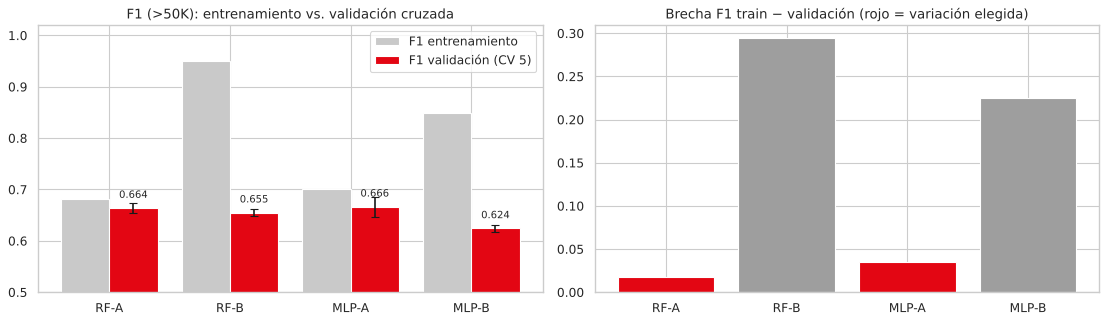

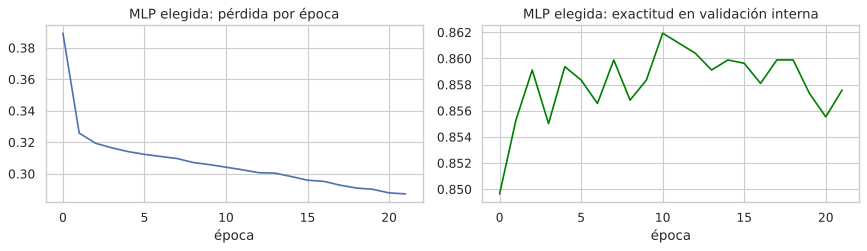

In [8]:
# Celda 9 — MLP: 2 variaciones con la misma validación cruzada
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def mlp(capas, alpha, early, max_iter):
    return Pipeline([
        ("preprocesamiento", construir_preprocesador()),
        ("modelo", MLPClassifier(hidden_layer_sizes=capas, activation="relu", solver="adam",
                                 alpha=alpha, batch_size=256, learning_rate_init=1e-3,
                                 max_iter=max_iter, early_stopping=early, validation_fraction=0.1,
                                 n_iter_no_change=10, random_state=RANDOM_STATE))])

variaciones_mlp = {
    "MLP-A · compacta + early stopping": mlp((64, 32), 1e-3, True, 300),
    "MLP-B · amplia sin early stopping": mlp((128, 64), 1e-4, False, 200),
}

t0 = time.time()
filas_mlp = [evaluar_variacion(n, p) for n, p in variaciones_mlp.items()]
tabla_mlp, elegida_mlp, descartada_mlp, modelo_mlp = elegir(filas_mlp, variaciones_mlp)
print(f"Validación cruzada de MLP completada en {time.time() - t0:.0f} s\n")
display(tabla_mlp.round(4))

a, b = tabla_mlp.loc[elegida_mlp], tabla_mlp.loc[descartada_mlp]
print(f"ELEGIDA: {elegida_mlp}")
print(f"  1) F1 validación: {a['F1 val']:.4f} vs {b['F1 val']:.4f}")
print(f"  2) Brecha train-val: {a['Brecha F1']:.3f} vs {b['Brecha F1']:.3f} (menor = menos sobreajuste)")
print(f"  3) Archivo: {a['Archivo (KB)']:.0f} KB vs {b['Archivo (KB)']:.0f} KB | "
      f"entrenamiento: {a['Entrenamiento (s)']:.1f} s vs {b['Entrenamiento (s)']:.1f} s")
red = modelo_mlp.named_steps["modelo"]
print(f"Épocas de la red elegida: {red.n_iter_}")

# Comparación visual de las 4 variaciones (solo datos de entrenamiento / validación cruzada)
tabla_var = pd.concat([tabla_rf, tabla_mlp])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(tabla_var))
axes[0].bar(x - 0.2, tabla_var["F1 train"], 0.4, label="F1 entrenamiento", color="#C9C9C9")
axes[0].bar(x + 0.2, tabla_var["F1 val"], 0.4, yerr=tabla_var["± F1 val"], capsize=4,
            label="F1 validación (CV 5)", color="#E30613")
axes[0].set_xticks(x, [v.split(" · ")[0] for v in tabla_var.index]); axes[0].set_ylim(0.5, 1.02)
axes[0].set_title("F1 (>50K): entrenamiento vs. validación cruzada"); axes[0].legend(loc="upper right")
for i, (tr, va) in enumerate(zip(tabla_var["F1 train"], tabla_var["F1 val"])):
    axes[0].text(i + 0.2, va + 0.02, f"{va:.3f}", ha="center", fontsize=9)
axes[1].bar(x, tabla_var["Brecha F1"], color=["#E30613" if v in (elegida_rf, elegida_mlp) else "#9E9E9E"
                                              for v in tabla_var.index])
axes[1].set_xticks(x, [v.split(" · ")[0] for v in tabla_var.index])
axes[1].set_title("Brecha F1 train − validación (rojo = variación elegida)")
plt.tight_layout(); plt.show()

if hasattr(red, "loss_curve_"):
    fig, ax = plt.subplots(1, 2 if red.early_stopping else 1, figsize=(11, 3.3), squeeze=False)
    ax[0][0].plot(red.loss_curve_); ax[0][0].set_title("MLP elegida: pérdida por época"); ax[0][0].set_xlabel("época")
    if red.early_stopping:
        ax[0][1].plot(red.validation_scores_, color="green"); ax[0][1].set_title("MLP elegida: exactitud en validación interna")
        ax[0][1].set_xlabel("época")
    plt.tight_layout(); plt.show()

## Celda 10. Evaluación de los modelos (conjunto de prueba)
Métricas obligatorias: **precision**, **recall** y **matriz de confusión**, calculadas para la clase positiva `>50K`. Se añaden F1, exactitud y ROC AUC como apoyo.
- **Precision (>50K):** de las personas que el modelo dice que ganan >50K, ¿qué proporción realmente gana >50K?
- **Recall (>50K):** de las personas que realmente ganan >50K, ¿qué proporción detecta el modelo?
- **F1:** media armónica de las dos anteriores (resume el equilibrio).
- **ROC AUC:** capacidad de ordenar a las personas por probabilidad, sin depender del umbral 0.5.

**F1, en palabras sencillas:** es una sola nota que resume precision y recall. Solo es alta si **ambas** son altas (si una es baja, el F1 baja mucho). Va de 0 a 1. Ejemplo con Random Forest: precision 0,80 y recall 0,60 → F1 = 2 × 0,80 × 0,60 / (0,80 + 0,60) ≈ 0,69. Un modelo que siempre dijera «≤50K» tendría F1 = 0 aunque su exactitud fuera 76 %.

**ROC AUC, en palabras sencillas:** tome al azar una persona que gana >50K y otra que gana ≤50K. El AUC es la probabilidad de que el modelo le asigne más probabilidad de >50K a la persona correcta. 0,5 = lanzar una moneda; 1 = perfecto. Un AUC de 0,92 significa que en 92 de cada 100 parejas el modelo ordena bien a las dos personas. No depende del umbral de 0,5.

In [9]:
# Celda 10 — Evaluación
modelos = {"Random Forest": modelo_rf, "Perceptrón multicapa (MLP)": modelo_mlp}
predicciones, probabilidades, filas = {}, {}, []

for nombre, m in modelos.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    predicciones[nombre], probabilidades[nombre] = pred, prob
    filas.append({"Modelo": nombre,
                  "Precision (>50K)": precision_score(y_test, pred),
                  "Recall (>50K)": recall_score(y_test, pred),
                  "F1 (>50K)": f1_score(y_test, pred),
                  "Precision (macro)": precision_score(y_test, pred, average="macro"),
                  "Recall (macro)": recall_score(y_test, pred, average="macro"),
                  "Exactitud": accuracy_score(y_test, pred),
                  "ROC AUC": roc_auc_score(y_test, prob)})

tabla = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla)

for nombre in modelos:
    print(f"\n=== {nombre} ===")
    print(classification_report(y_test, predicciones[nombre], target_names=["<=50K", ">50K"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_test, predicciones[nombre]).ravel()
    print(f"Matriz de confusión → VN={tn}  FP={fp}  FN={fn}  VP={tp}")

# Interpretación automática con los valores reales obtenidos
mejor_f1 = tabla["F1 (>50K)"].idxmax()
otro = [n for n in modelos if n != mejor_f1][0]
print("\nINTERPRETACIÓN")
for nombre, r in tabla.iterrows():
    print(f"- {nombre}: cuando predice '>50K' acierta el {r['Precision (>50K)']:.1%} de las veces (precision) "
          f"y detecta el {r['Recall (>50K)']:.1%} de quienes realmente ganan >50K (recall).")
print(f"- Mejor F1 en la clase >50K: {mejor_f1} ({tabla.loc[mejor_f1, 'F1 (>50K)']:.4f} vs "
      f"{tabla.loc[otro, 'F1 (>50K)']:.4f}); diferencia de "
      f"{abs(tabla.loc[mejor_f1, 'F1 (>50K)'] - tabla.loc[otro, 'F1 (>50K)']):.4f}.")

,Precision (>50K),Recall (>50K),F1 (>50K),Precision (macro),Recall (macro),Exactitud,ROC AUC
Modelo,,,,,,,
Random Forest,0.7963,0.6040,0.687,0.8402,0.7777,0.8682,0.9195
Perceptrón multicapa (MLP),0.7246,0.6353,0.677,0.8071,0.7796,0.8549,0.9097



=== Random Forest ===
              precision    recall  f1-score   support

       <=50K     0.8842    0.9514    0.9165      7422
        >50K     0.7963    0.6040    0.6870      2336

    accuracy                         0.8682      9758
   macro avg     0.8402    0.7777    0.8017      9758
weighted avg     0.8631    0.8682    0.8616      9758

Matriz de confusión → VN=7061  FP=361  FN=925  VP=1411

=== Perceptrón multicapa (MLP) ===
              precision    recall  f1-score   support

       <=50K     0.8895    0.9240    0.9064      7422
        >50K     0.7246    0.6353    0.6770      2336

    accuracy                         0.8549      9758
   macro avg     0.8071    0.7796    0.7917      9758
weighted avg     0.8500    0.8549    0.8515      9758

Matriz de confusión → VN=6858  FP=564  FN=852  VP=1484

INTERPRETACIÓN
- Random Forest: cuando predice '>50K' acierta el 79.6% de las veces (precision) y detecta el 60.4% de quienes realmente ganan >50K (recall).
- Perceptrón multic

## Celda 11. Visualización y comparación
Matrices de confusión de ambos modelos, comparación de métricas, curvas ROC y variables más importantes según Random Forest.

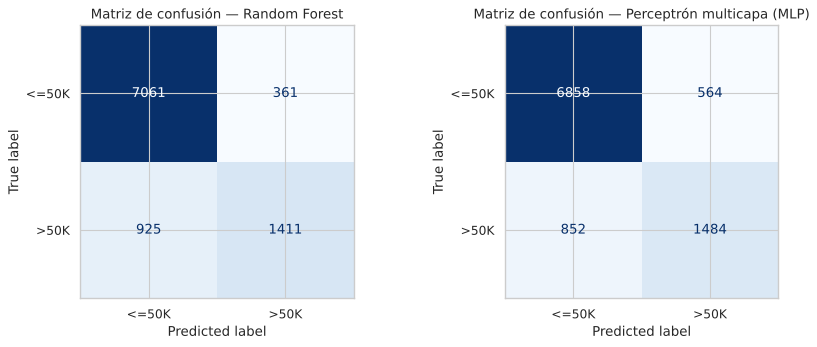

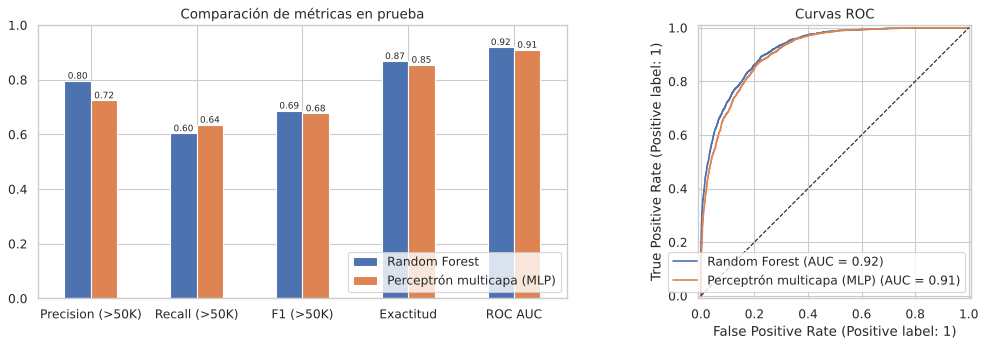

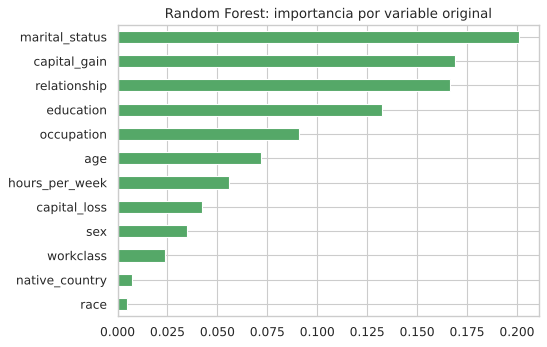

marital_status    0.201
capital_gain      0.169
relationship      0.166
education         0.132
occupation        0.091
age               0.072
hours_per_week    0.056
capital_loss      0.042
sex               0.035
workclass         0.024
native_country    0.007
race              0.005
dtype: float64

CONCLUSIÓN (calculada con los resultados de esta ejecución)
- Exactitud: RF=0.868, MLP=0.855; ROC AUC: RF=0.919, MLP=0.910.
- Mayor precision (>50K): Random Forest. Mayor recall (>50K): Perceptrón multicapa (MLP).
- Con F1 de la clase >50K como criterio principal (equilibrio entre precision y recall en una clase minoritaria), el mejor modelo es: Random Forest.
- Ambos modelos superan ampliamente al clasificador trivial (siempre '<=50K', exactitud ≈ 0.761 y recall 0). El error más frecuente son falsos negativos: personas con ingreso >50K clasificadas como <=50K.


In [10]:
# Celda 11 — Visualización y comparación
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nombre in zip(axes, modelos):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=["<=50K", ">50K"],
                                            cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión — {nombre}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tabla[["Precision (>50K)", "Recall (>50K)", "F1 (>50K)", "Exactitud", "ROC AUC"]].T.plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0, 1); axes[0].set_title("Comparación de métricas en prueba"); axes[0].legend(loc="lower right")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=8)
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_test, probabilidades[nombre], name=nombre, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Curvas ROC")
plt.tight_layout(); plt.show()

# Importancia de variables (Random Forest, agregando las columnas one-hot por variable original)
nombres = modelo_rf.named_steps["preprocesamiento"].get_feature_names_out()
imp = pd.Series(modelo_rf.named_steps["modelo"].feature_importances_, index=nombres)
imp_original = imp.groupby(lambda s: next(c for c in FEATURES if s.split("__", 1)[1].startswith(c))).sum()
imp_original.sort_values().plot.barh(figsize=(7, 4.5), color="#55A868",
                                     title="Random Forest: importancia por variable original")
plt.tight_layout(); plt.show()
print(imp_original.sort_values(ascending=False).round(3))

# Conclusión generada a partir de los resultados reales
r = tabla
print("\nCONCLUSIÓN (calculada con los resultados de esta ejecución)")
print(f"- Exactitud: RF={r.loc['Random Forest','Exactitud']:.3f}, MLP={r.loc['Perceptrón multicapa (MLP)','Exactitud']:.3f}; "
      f"ROC AUC: RF={r.loc['Random Forest','ROC AUC']:.3f}, MLP={r.loc['Perceptrón multicapa (MLP)','ROC AUC']:.3f}.")
mejor_prec = r["Precision (>50K)"].idxmax(); mejor_rec = r["Recall (>50K)"].idxmax()
print(f"- Mayor precision (>50K): {mejor_prec}. Mayor recall (>50K): {mejor_rec}.")
print(f"- Con F1 de la clase >50K como criterio principal (equilibrio entre precision y recall en una clase "
      f"minoritaria), el mejor modelo es: {mejor_f1}.")
print("- Ambos modelos superan ampliamente al clasificador trivial (siempre '<=50K', exactitud ≈ "
      f"{1 - y_test.mean():.3f} y recall 0). El error más frecuente son falsos negativos: personas con ingreso "
      ">50K clasificadas como <=50K.")

**Selección de variaciones (validación cruzada de 5 particiones, solo entrenamiento):** RF-A (regularizado) superó a RF-B (árboles completos) en F1 de validación (0.664 vs 0.655), con brecha de sobreajuste mucho menor (0.017 vs 0.295) y un archivo 6.5 veces más liviano (8 MB vs 53 MB). MLP-A (compacta + early stopping) superó a MLP-B (amplia sin early stopping) en F1 (0.666 vs 0.624), brecha (0.035 vs 0.225) y tiempo (4 s vs 63 s). En los dos algoritmos ganó la variación **regularizada**: las variaciones más complejas memorizan el entrenamiento (F1 train 0.95 y 0.85) sin generalizar mejor.

**Resultados de la ejecución de referencia** (scikit-learn 1.9.1, `random_state=42`; si se re-ejecuta en Colab con otra versión de las bibliotecas los valores pueden variar en milésimas, y la conclusión impresa arriba se recalcula sola):

| Modelo | Precision >50K | Recall >50K | F1 >50K | Exactitud | ROC AUC |
|---|---|---|---|---|---|
| Random Forest | 0.796 | 0.604 | 0.687 | 0.868 | 0.920 |
| MLP | 0.725 | 0.635 | 0.677 | 0.855 | 0.910 |

- **Random Forest** es más *preciso*: comete menos falsos positivos (361 vs 564), es decir, cuando dice ">50K" se equivoca menos.
- **MLP** tiene algo más de *recall*: detecta más personas de ingreso alto (1 484 vs 1 411) a costa de más falsos positivos.
- Por F1, exactitud y ROC AUC, **Random Forest es el mejor modelo** en este problema, aunque la diferencia es pequeña (≈ 1 punto de F1).
- En ambos el error dominante son los **falsos negativos** (≈ 37–40 % de las personas con >50K no se detectan), consecuencia del desbalance de clases y del umbral 0.5. Si el caso de uso necesitara detectar más personas de ingreso alto, se podría bajar el umbral (sube recall, baja precision).

## Celda 12. Guardado de modelos y preprocesamiento
Se guarda **cada Pipeline completo** (preprocesador ajustado + modelo) con `joblib`. Así el archivo `.joblib` contiene la imputación, el `log1p`, el escalado y el one-hot aprendidos en entrenamiento, y Streamlit solo debe enviar un DataFrame con las 12 columnas originales.

Archivos generados en `modelos/`:
- `modelo_random_forest.joblib` — Pipeline Random Forest.
- `modelo_mlp.joblib` — Pipeline MLP.
- `metadatos.json` — orden de columnas, categorías válidas y rangos numéricos vistos en entrenamiento (la app los usa para construir y validar los campos), nombres de los modelos y métricas.

**¿Cómo se "descargan los pesos" del modelo?** Un modelo entrenado es un objeto de Python en memoria. `joblib.dump()` lo **serializa** (lo convierte en un archivo binario) con todo lo aprendido: en el MLP, las matrices de pesos `coefs_` y los sesgos `intercepts_` de cada capa; en Random Forest, la estructura de los 300 árboles (variable y umbral de cada nodo, probabilidades de cada hoja); y en el preprocesador, las medianas, modas, medias, desviaciones y categorías vistas. En Colab el archivo queda en el disco temporal de la sesión y se descarga con `files.download()` (Celda 14) o desde el panel de archivos. En el computador, `joblib.load()` lo **deserializa** y el modelo queda listo para `predict()` sin volver a entrenar.

Además se genera `requirements.txt` con las **versiones exactas** de esta sesión: los modelos deben cargarse con la misma versión de scikit-learn con la que se guardaron.

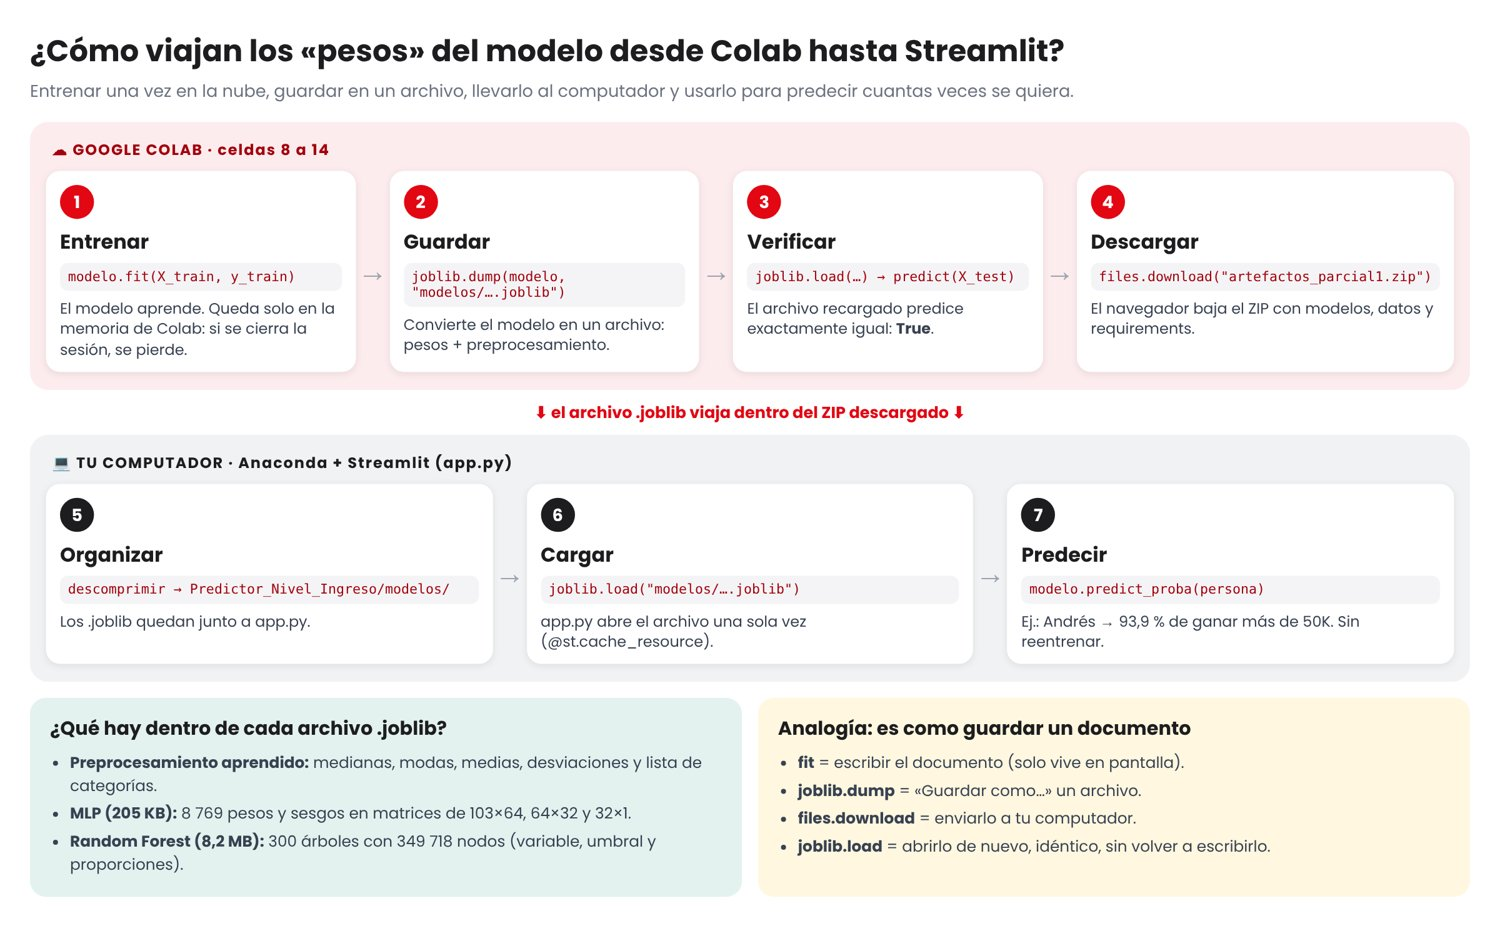

**El código de esta celda, paso a paso**
1. `ARCHIVOS_MODELOS = {...}`: define el nombre de archivo de cada modelo (los mismos que busca `app.py`).
2. `joblib.dump(modelos[nombre], DIR_MODELOS / archivo, compress=3)`: guarda cada Pipeline completo en `modelos/`. `compress=3` reduce el tamaño del archivo.
3. `metadatos = {...}` y `json.dump(...)`: guarda en `metadatos.json` el orden de las columnas, las categorías válidas, las modas, los rangos, las métricas y las versiones. La app lo usa para armar el formulario.
4. `Path("requirements.txt").write_text(...)`: escribe las versiones exactas de las librerías usadas.
5. `red.coefs_` y `red.intercepts_`: muestra la forma de las matrices de pesos del MLP (103×64, 64×32, 32×1) y cuenta 8 769 parámetros; `bosque.estimators_` cuenta los 300 árboles y sus nodos.
6. `joblib.load(...)` + `(m.predict(X_test) == predicciones[nombre]).all()`: vuelve a abrir cada archivo y comprueba que predice exactamente lo mismo que el modelo en memoria (`True`).

In [11]:
# Celda 12 — Guardado
ARCHIVOS_MODELOS = {"Random Forest": "modelo_random_forest.joblib",
                    "Perceptrón multicapa (MLP)": "modelo_mlp.joblib"}
for nombre, archivo in ARCHIVOS_MODELOS.items():
    joblib.dump(modelos[nombre], DIR_MODELOS / archivo, compress=3)

metadatos = {
    "dataset": "Adult / Census Income (UCI Machine Learning Repository, id 2)",
    "url_dataset": URL_FICHA,
    "objetivo": "income (1 = >50K USD/año, 0 = <=50K USD/año)",
    "clases": {"0": "<=50K", "1": ">50K"},
    "features": FEATURES,
    "numericas": NUM_SIMPLES + NUM_SESGADAS,
    "categoricas": CATEGORICAS,
    "categorias": {c: sorted(X_train[c].dropna().unique().tolist()) for c in CATEGORICAS},
    "moda": {c: X_train[c].mode()[0] for c in CATEGORICAS},
    "rangos": {c: {"min": int(X_train[c].min()), "max": int(X_train[c].max()),
                   "mediana": float(X_train[c].median())} for c in NUM_SIMPLES + NUM_SESGADAS},
    "modelos": ARCHIVOS_MODELOS,
    "variaciones_elegidas": {"Random Forest": elegida_rf, "Perceptrón multicapa (MLP)": elegida_mlp},
    "metricas_prueba": tabla.to_dict(orient="index"),
    "versiones": {"python_sklearn": sklearn.__version__, "pandas": pd.__version__,
                  "numpy": np.__version__, "joblib": joblib.__version__},
}
with open(DIR_MODELOS / "metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

# requirements.txt con las versiones exactas de este entorno
import matplotlib
requisitos = f'''# Versiones registradas al entrenar (Celda 12 del notebook)
streamlit>=1.36
scikit-learn=={sklearn.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
joblib=={joblib.__version__}
# Solo para ejecutar el notebook fuera de Colab:
matplotlib=={matplotlib.__version__}
seaborn=={sns.__version__}
'''
Path("requirements.txt").write_text(requisitos, encoding="utf-8")

# ¿Qué son los "pesos" que se guardan?
red = modelo_mlp.named_steps["modelo"]
n_param = sum(w.size for w in red.coefs_) + sum(b.size for b in red.intercepts_)
print("MLP → matrices de pesos (coefs_) por capa:", [w.shape for w in red.coefs_],
      "| sesgos (intercepts_):", [b.shape for b in red.intercepts_], "| parámetros totales:", f"{n_param:,}")
bosque = modelo_rf.named_steps["modelo"]
print("Random Forest →", len(bosque.estimators_), "árboles | nodos totales:",
      f"{sum(t.tree_.node_count for t in bosque.estimators_):,}", "(umbrales y probabilidades de cada hoja)\n")

# Comprobación de que los archivos existen y se pueden cargar
print("Archivos guardados:")
for ruta in sorted(DIR_MODELOS.iterdir()):
    print(f"  {ruta}  ({ruta.stat().st_size / 1024:,.0f} KB)")
print("  requirements.txt\n" + requisitos)
for nombre, archivo in ARCHIVOS_MODELOS.items():
    m = joblib.load(DIR_MODELOS / archivo)
    iguales = (m.predict(X_test) == predicciones[nombre]).all()
    print(f"{archivo}: cargado correctamente; predicciones idénticas al modelo en memoria → {iguales}")

MLP → matrices de pesos (coefs_) por capa: [(103, 64), (64, 32), (32, 1)] | sesgos (intercepts_): [(64,), (32,), (1,)] | parámetros totales: 8,769
Random Forest → 300 árboles | nodos totales: 349,718 (umbrales y probabilidades de cada hoja)

Archivos guardados:
  modelos/metadatos.json  (4 KB)
  modelos/modelo_mlp.joblib  (205 KB)
  modelos/modelo_random_forest.joblib  (8,389 KB)
  requirements.txt
# Versiones registradas al entrenar (Celda 12 del notebook)
streamlit>=1.36
scikit-learn==1.9.1
pandas==3.0.5
numpy==2.5.3
joblib==1.6.0
# Solo para ejecutar el notebook fuera de Colab:
matplotlib==3.11.2
seaborn==0.13.2

modelo_random_forest.joblib: cargado correctamente; predicciones idénticas al modelo en memoria → True
modelo_mlp.joblib: cargado correctamente; predicciones idénticas al modelo en memoria → True


## Celda 13. Prueba de inferencia
Se cargan los Pipelines desde disco (como hará Streamlit) y se predicen **dos personas con características distintas**. El modelo devuelve la clase (`0` = `<=50K`, `1` = `>50K`) y `predict_proba` devuelve la probabilidad estimada de cada clase; se reporta la probabilidad de `>50K` (umbral de decisión 0.5).

**Línea por línea**
1. `modelos_cargados = {n: joblib.load(...) ...}`: abre los dos archivos `.joblib` y guarda los modelos en un diccionario: `{"Random Forest": ..., "Perceptrón multicapa (MLP)": ...}`.
2. `ejemplos = pd.DataFrame([{...}, {...}], columns=FEATURES)`: **crea los perfiles**. Cada `{...}` es una persona escrita como diccionario «columna: valor», con los valores originales del censo (por ejemplo `"Masters"`, no «Maestría»). `columns=FEATURES` obliga a que las 12 columnas queden en el mismo orden del entrenamiento. Persona 1 (Andrés): 45 años, maestría, casado, directivo, 50 h/semana y 15 024 USD de ganancias de capital. Persona 2 (Laura): 23 años, bachiller, soltera, otros servicios, 25 h/semana.
3. `display(ejemplos)`: muestra la tabla con los dos perfiles.
4. `resultados = []`: lista vacía donde se irán guardando las respuestas.
5. `for i in range(len(ejemplos))`: recorre las personas (i = 0 y i = 1).
6. `for nombre, m in modelos_cargados.items()`: para cada persona, recorre los dos modelos.
7. `fila = ejemplos.iloc[[i]]`: toma **una sola persona** como tabla de 1 fila (los dobles corchetes mantienen el formato de tabla que espera el Pipeline).
8. `clase = int(m.predict(fila)[0])`: pide la clase. El Pipeline primero transforma la fila (imputar, log1p, escalar, one-hot → 103 números) y luego el modelo decide: 1 si la probabilidad de >50K es ≥ 0,5; 0 si no.
9. `p = float(m.predict_proba(fila)[0, 1])`: pide las probabilidades `[P(≤50K), P(>50K)]` y se queda con la segunda, `[0, 1]` = fila 0, columna 1.
10. `resultados.append({...})`: guarda persona, modelo, clase en texto (`CLASES[clase]`) y probabilidad redondeada.
11. `display(pd.DataFrame(resultados))`: muestra las 4 predicciones (2 personas × 2 modelos).

**¿Qué pasa por dentro con Andrés?** El preprocesador convierte sus 12 datos en 103 números: edad 45 → 0,47 (desviaciones sobre la media de 38,6 años); horas 50 → 0,77; ganancias 15 024 → log1p = 9,62 → 3,64 (muy por encima de lo normal); y un 1 en las columnas `education_Masters`, `marital_status_Married-civ-spouse`, `occupation_Exec-managerial`, etc. (0 en las demás). Con ese vector, **los 300 árboles** del Random Forest votan por >50K y el promedio de sus probabilidades da **0,939**. En el MLP, los 103 números pasan por 64 neuronas (30 se activan), luego por 32 (18 se activan) y la salida logística da **0,976**.

In [12]:
# Celda 13 — Inferencia con los modelos guardados
# 1) Abrir los dos Pipelines guardados (como hará Streamlit)
modelos_cargados = {n: joblib.load(DIR_MODELOS / a) for n, a in ARCHIVOS_MODELOS.items()}

# 2) Crear los perfiles: una persona por diccionario, con los valores originales del censo
ejemplos = pd.DataFrame([
    {"age": 45, "workclass": "Private", "education": "Masters", "marital_status": "Married-civ-spouse",
     "occupation": "Exec-managerial", "relationship": "Husband", "race": "White", "sex": "Male",
     "capital_gain": 15024, "capital_loss": 0, "hours_per_week": 50, "native_country": "United-States"},
    {"age": 23, "workclass": "Private", "education": "HS-grad", "marital_status": "Never-married",
     "occupation": "Other-service", "relationship": "Own-child", "race": "White", "sex": "Female",
     "capital_gain": 0, "capital_loss": 0, "hours_per_week": 25, "native_country": "United-States"},
], columns=FEATURES)            # mismo orden de columnas que en el entrenamiento
display(ejemplos)

resultados = []                                    # aquí se guardan las respuestas
for i in range(len(ejemplos)):                     # recorre las personas (0 y 1)
    for nombre, m in modelos_cargados.items():     # recorre los dos modelos
        fila = ejemplos.iloc[[i]]                  # una persona, como tabla de 1 fila
        clase = int(m.predict(fila)[0])            # 0 = <=50K, 1 = >50K (umbral 0.5)
        p = float(m.predict_proba(fila)[0, 1])     # probabilidad de >50K
        resultados.append({"Ejemplo": i + 1, "Modelo": nombre, "Clase predicha": CLASES[clase],
                           "P(>50K)": round(p, 4)})
display(pd.DataFrame(resultados))
print("Interpretación: 'P(>50K)' es la probabilidad estimada de que la persona gane más de 50K USD/año. "
      "Si es ≥ 0.5 el modelo asigna la clase '>50K'. Valores cercanos a 0.5 indican casos dudosos.")

,age,workclass,education,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,45,Private,Masters,Married-civ-spouse,Exec-managerial,Husband,White,Male,15024,0,50,United-States
1,23,Private,HS-grad,Never-married,Other-service,Own-child,White,Female,0,0,25,United-States


,Ejemplo,Modelo,Clase predicha,P(>50K)
0,1,Random Forest,>50K,0.9390
1,1,Perceptrón multicapa (MLP),>50K,0.9761
2,2,Random Forest,<=50K,0.0005
3,2,Perceptrón multicapa (MLP),<=50K,0.0002


Interpretación: 'P(>50K)' es la probabilidad estimada de que la persona gane más de 50K USD/año. Si es ≥ 0.5 el modelo asigna la clase '>50K'. Valores cercanos a 0.5 indican casos dudosos.


## Celda 14 (opcional). Descargar los archivos generados desde Colab
Empaqueta `modelos/`, `datos/` y `requirements.txt` en `artefactos_parcial1.zip` y lo descarga al computador. Después copie su contenido a la carpeta del proyecto junto con `app.py` y este notebook (*Archivo → Descargar → Descargar .ipynb*).

In [13]:
# Celda 14 — Descarga (solo funciona dentro de Google Colab)
import shutil, os
os.makedirs("_artefactos", exist_ok=True)
for carpeta in ["modelos", "datos"]:
    shutil.copytree(carpeta, f"_artefactos/{carpeta}", dirs_exist_ok=True)
shutil.copy("requirements.txt", "_artefactos/requirements.txt")
zip_path = shutil.make_archive("artefactos_parcial1", "zip", "_artefactos")
print("Creado:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("No se está ejecutando en Colab: el ZIP queda en la carpeta actual.")

Creado: /home/claude/Predictor_Nivel_Ingreso/artefactos_parcial1.zip
No se está ejecutando en Colab: el ZIP queda en la carpeta actual.
